# Part 1 — 데이터 프로파일링

**목적** 전처리·길이 설정·분할 전략의 근거가 될 통계를 이 컴퓨터에서 직접 잰다.

**실행한 것**

```
python scripts/profile_data.py --split train                   # train 전체 통계 (약 50초)
python scripts/profile_data.py --split valid --integrity-only  # valid 는 건수·ID·유형/주제만
```

**valid를 어디까지 봤나** valid는 최종 holdout이다. `header.dialogueInfo`만 스트리밍으로 읽었고,
대화·요약문(`body`)은 파이썬 객체로 만들지도 않았다. 길이·태그·요약 통계는 전부 train에서만 냈다.

이 노트북은 결과 파일(`artifacts/profile/`)을 읽어서 보여주기만 한다.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

P = Path("../artifacts/profile")
train = json.loads((P / "train_stats.json").read_text(encoding="utf-8"))
valid = json.loads((P / "valid_integrity.json").read_text(encoding="utf-8"))
samples = json.loads((P / "train_samples.json").read_text(encoding="utf-8"))

## 1. 무결성 — ID 교차 중복 검사 (누수 전체 검증은 아님)

train과 valid에 같은 대화가 있으면 test 점수가 부풀려진다. 가장 먼저 확인할 것.

In [2]:
pd.Series({
    "train 건수": train["n_items"],
    "valid 건수": valid["n_items"],
    "train 내부 ID 중복": train["dup_within_train"],
    "valid 내부 ID 중복": valid["dup_within_valid"],
    "train↔valid 교차 중복 (누수)": valid["overlap_with_train"],
    "파일명↔topic 불일치 (train)": train["topic_file_mismatch"],
    "파일명↔topic 불일치 (valid)": valid["topic_file_mismatch"],
}, name="값").to_frame()

,값
train 건수,279992
valid 건수,35004
train 내부 ID 중복,0
valid 내부 ID 중복,0
train↔valid 교차 중복 (누수),0
파일명↔topic 불일치 (train),0
파일명↔topic 불일치 (valid),0


**파일명↔topic 불일치**는 처음 실행에서 train 20,428 / valid 2,554건이 나왔다.
`일과직업.json` 파일의 `topic` 값이 `일과 직업`(띄어쓰기 있음)인데 매핑표가 `일과직업`으로 틀려 있었기 때문이다.
`src/data_loader.py`의 `TOPIC_BY_FILE`을 고친 뒤 0건이 됐다. Part 2의 주제 층화 분할이 이 매핑에 기대므로 여기서 잡아야 했다.

## 2. 분포 — 유형·주제는 train과 valid가 같은 비율인가 (층화 확인)

In [3]:
def dist(d): return pd.Series({k: v["pct"] for k, v in d.items()})
pd.DataFrame({"train %": dist(train["topic"]), "valid %": dist(valid["topic"])})

,train %,valid %
개인 및 관계,25.404,25.403
주거와 생활,16.136,16.135
여가 생활,12.589,12.590
식음료,10.780,10.779
상거래(쇼핑),9.392,9.393
행사,7.621,7.622
일과 직업,7.296,7.296
미용과 건강,6.096,6.096
시사/교육,4.685,4.685


In [4]:
pd.DataFrame({"train %": dist(train["type"]), "valid %": dist(valid["type"]),
              "train 건수": pd.Series({k: v["n"] for k, v in train["type"].items()})})

,train %,valid %,train 건수
일상 대화,99.426,99.463,278384
토론 대화,0.574,0.537,1608


주제·유형 비율이 소수 둘째 자리까지 같다 → 공식 분할이 층화되어 있다.
**토론 대화는 0.57%(1,608건)뿐**이라 형식("~에 대해서 토론한다")을 학습하기 어렵다. 평가에서 별도 슬라이스로 본다.

## 3. 길이 — 글자 수가 아니라 토큰 수로 한도를 정한다

모델이 실제로 받는 건 토큰이다. 글자 수로 한도를 추정하면 틀린다.

In [5]:
rows = {"발화 수": train["num_utterances"], "턴 수": train["num_turns"],
        "대화 글자 수(발화 합)": train["dialogue_chars"], "요약 글자 수": train["summary_chars"],
        "source 토큰 (plain)": train["tokens"]["source_plain"], "source 토큰 (speaker)": train["tokens"]["source_speaker"],
        "target 토큰": train["tokens"]["target"]}
cols = ["mean", "p50", "p90", "p95", "p99", "p99.9", "max"]
pd.DataFrame({k: {c: v[c] for c in cols} for k, v in rows.items()}).T

,mean,p50,p90,p95,p99,p99.9,max
발화 수,11.27,10.0,16.0,18.0,23.0,29.000,30.0
턴 수,5.84,5.0,8.0,9.0,13.0,17.000,20.0
대화 글자 수(발화 합),120.62,108.0,189.0,225.0,323.0,506.000,2029.0
요약 글자 수,42.02,40.0,62.0,69.0,77.0,91.000,174.0
source 토큰 (plain),102.13,93.0,155.0,183.0,256.0,387.000,1570.0
source 토큰 (speaker),158.50,147.0,226.0,262.0,351.0,490.009,1650.0
target 토큰,28.55,27.0,42.0,46.0,53.0,63.000,116.0


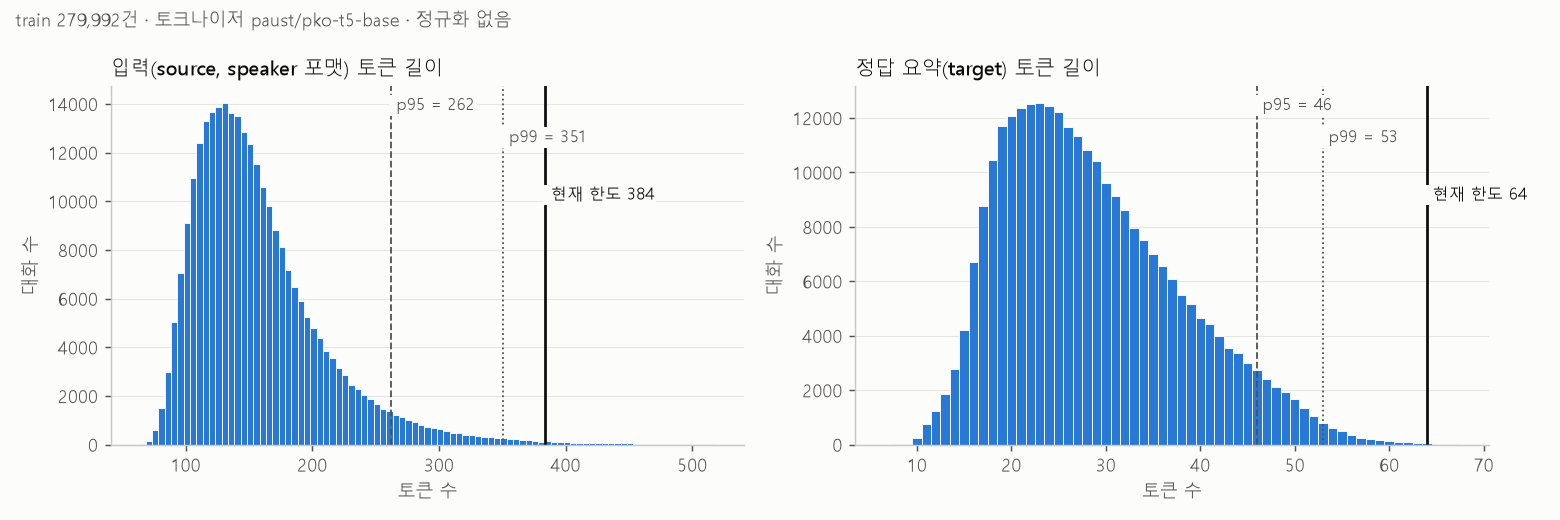

In [6]:
display(Image(filename=str(P / 'length_hist.png')))

In [7]:
# 한도별로 잘리지 않는 비율(%)
pd.DataFrame({"plain": train["tokens"]["source_plain"]["coverage_pct"],
              "speaker": train["tokens"]["source_speaker"]["coverage_pct"]}).T

,128,192,256,320,384,512
plain,80.115,95.998,99.021,99.708,99.894,99.980
speaker,32.390,80.089,94.430,98.283,99.444,99.929


In [8]:
pd.Series(train['tokens']['target']['coverage_pct'], name='target 무절단 %').to_frame().T

,32,48,64,96
target 무절단 %,69.468,96.625,99.928,99.999


### 결정

| 항목 | 내용 |
|---|---|
| 선택 | `max_source_length` 384, `max_target_length` 64 유지 |
| 근거 | `speaker` 포맷 p99 351 → 384에서 99.44% 무절단. target p99.9 63 → 64에서 99.93% 무절단 |
| 대안 | `plain` 포맷이면 256에서 99.02% 무절단 → batch 8 가능 (Part 0에서 8×256은 VRAM 안에 들어갔다) |
| 되돌릴 조건 | Part 2 포맷 비교에서 `plain`이 이기거나, 정규화 후 `speaker` p99가 256 이하로 내려가면 256 + batch 8 |

화자 표시(`P01: `)가 발화마다 약 5토큰씩 붙어서 `speaker`가 평균 56토큰 길다. 이 길이 비용이 성능으로 돌아오는지는 Part 2에서 비교한다.

## 4. 비식별화 태그 — 입력에만 있고 요약문에는 0건

In [9]:
pd.DataFrame({"대화 속 등장 횟수": train["tags_in_dialogue"]}).assign(
    요약문속=lambda d: [train["tags_in_summary"].get(k, 0) for k in d.index])

,대화 속 등장 횟수,요약문속
#@이름#,87540,0
#@시스템#,41919,0
#@이모티콘#,25024,0
#@기타#,15934,0
#@URL#,3286,0
#@소속#,1859,0
#@주소#,1176,0
#@계정#,620,0
#@번호#,386,0
#@금융#,301,0


### 새로 발견한 것 — 태그 뒤에 하위 유형이 붙는다

`#@시스템#`은 **항상** `#@시스템#사진#`처럼 하위 유형과 `#`이 한 번 더 붙는다. `#@이모티콘#`도 9.4%가 그렇다.
`configs/base.yaml`의 `drop_tags`를 문자열 그대로 지우면 `사진#` 같은 잔해가 입력에 남는다.
→ Part 2의 제거 규칙은 하위 유형까지 포함한 패턴으로 만든다.

In [10]:
sub = train["subtags_in_dialogue"]
print("하위 유형이 붙은 횟수:", sub["total"], "/ 전체:", {t: train["tags_in_dialogue"][f"#@{t}#"] for t in sub["total"]})
pd.Series(sub["top"], name="횟수").head(15).to_frame()

하위 유형이 붙은 횟수: {'시스템': 41919, '이모티콘': 2356} / 전체: {'시스템': 41919, '이모티콘': 25024}


,횟수
#@시스템#사진#,33712
#@시스템#검색#,4713
#@시스템#기타#,2067
#@시스템#동영상#,814
#@이모티콘#흑흑#,317
#@이모티콘#하하#,236
#@시스템#파일#,217
#@시스템#삭제#,167
#@시스템#송금#,148
#@이모티콘#헉#,104


## 5. 요약문 형식 점검 (train 전수)

In [11]:
pd.DataFrame({k: {"건수": v["n"]} for k, v in train["summary_quality"].items()}).T

,건수
empty,0
has_tag,0
dot_ge2,558
multi_sentence,55
short_lt10,0
edge_whitespace,0


- 빈 문자열·태그·10자 미만·앞뒤 공백 **0건**, 마지막 글자는 전부 `.`
- `dot_ge2`(마침표 2개 이상) 558건은 대부분 소수점(`3.5킬로`)이라 문장 수 판단에 쓰지 않는다
- `multi_sentence`(문장 끝 부호 뒤에 공백+글자) 55건(0.02%)은 인용된 감탄·실제 2문장·반복이 섞여 있다.
  **정답은 수정하지 않는다** 원칙대로 그대로 둔다

## 6. 눈으로 보기 — train 샘플 5건 (고정 시드)

숫자만 보면 놓치는 것들이 보인다: 짧은 발화가 많고, `ㅋㅋ`·오타·줄임말이 많으며, 요약은 대화에 없는 표현으로 다시 쓴다.

In [12]:
for x in samples[:5]:
    print(f"[{x['topic']}] {x['id'][:8]}")
    print(x["source_speaker"])
    print("→ 요약:", x["summary"])
    print()

[개인 및 관계] 9fb9084c
대화 요약: P01: 밥먹고 오죠?
P02: 아침만 먹고 ㅋㅋ
P02: 갈거같은데요
P02: 먹고 오시면 먹구가구
P01: 먹고와여~ 간단하게라두~ 시간이 너무 늦어서 ㅎㅎ
P02: 라면 하나 먹고 갈께요
P01: 오키오키~ 가서 배고프면 딴거 사먹어도 되니까 ㅋㅋ 나도 간단하게 머 먹고갈께여
P02: 오 알겟습니당
→ 요약: 시간이 너무 늦어서 라면을 하나 먹고 간다고 한다.

[여가 생활] ee95d176
대화 요약: P01: 아 나웃긴사진 있어 #@기타#ㅋㄱㄱ
P01: 혹시 노홍철
P01: 초콜릿분수짤 아닠ㅋㅋㅋㅋㄱㄱㄱ
P01: 나 초코빵 먹는데
P02: 아 모르지만
P02: 뭔데개웃겨 벌써부터
P02: ㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋ
P01: 믹고 시간차로
P01: 감격하는 모습
P01: #@시스템#사진#
P02: ㅋㅋㅋㅋㅋㅋㅋㅋㅋㅋ
P02: 아머야 생각보다 정상적인뎈ㅋㅋㅋ
→ 요약: 노홍철 초콜릿 분수 사진을 보여주니 생각보다 정상적이라 말한다.

[미용과 건강] 5c3b7f7b
대화 요약: P01: 너도 해여해
P01: 돼지야
P02: 화이팅
P01: 우리셋다 최고~~~
P01: 무조건 성공하기!
P03: ㅋㅋ 귀여워
P03: 화이팅
P01: #@시스템#사진#
P02: 돼지
P02: ㅂ10킬로.빼자 아자아자.화이팅
→ 요약: 우리 셋 다 성공해서 10킬로를 빼자고 하였다.

[여가 생활] 7272552e
대화 요약: P01: #@시스템#사진#
P01: 지금 1위하는 영화 평점
P02: 나#@이름#
P02: 싫어
P02: 재수없어
P01: 표정이
P01: 재수없긴해
P02: 말하는것도
P02: 재수없음
→ 요약: 지금 1위 하는 영화 평점을 공유하자 표정과 말 하는 게 재수 없다며 등장인물을 평가한다.

[일과 직업] 9a526ebb
대화 요약: P01: 나우우래
P02: 왜우우래
P02: (사실알고이쪄)
P01: 힝
P02: 그럼#@이름#회식할때도
P02: 거의모르는사람들이랑
P02: 해야하눈고야?
P01: 그런가바ㅜㅜㅜㅜ
